# 03 — Modeling and Evaluation


Goals:
- Establish a majority-class baseline
- Train candidate models
- Use consistent preprocessing and splits
- Compare classification metrics
- Add cross-validation and tuning


## Baseline Classification

Before comparing machine learning models, we establish a naive baseline.

Because the target is imbalanced, the baseline classifier predicts the
most frequent class for every observation.

Future models should be compared against this baseline rather than
considering accuracy in isolation.

## Load the data

In [106]:
import sys
from pathlib import Path

import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline


CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR
sys.path.append(str(PROJECT_ROOT))

from src.evaluation import (
    evaluate_binary_classifier,
    get_confusion_matrix,
    results_to_dataframe,
    plot_confusion_matrix,
    plot_roc_curve,
    cross_validate_classifier,
    cross_validation_results_to_dataframe,
)

from src.preprocessing import build_preprocessor
from src.models import get_student3_models

DATA_PATH = PROJECT_ROOT / "data" / "bank-full.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Download bank-full.csv and place it in the data/ folder."
    )

df = pd.read_csv(
    DATA_PATH,
    sep=";",
)




## Temporary Train/Test Split

In [107]:
df.head()

X = df.drop(columns=["y"])

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 36168
Testing observations: 9043


## Create a temporary baseline model

In [108]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    X_train,
    y_train,
)

baseline_predictions = baseline.predict(
    X_test
)



## Evaluate the baseline model


In [109]:
baseline_probabilities = baseline.predict_proba(
    X_test
)[:, 1]


baseline_results = evaluate_binary_classifier(
    model_name="Majority Class Baseline",
    y_true=y_test,
    y_pred=baseline_predictions,
    y_score=baseline_probabilities,
)

baseline_results

{'model': 'Majority Class Baseline',
 'accuracy': 0.8830034280659074,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5}

## Comparison table

In [110]:


results = [
    baseline_results
]

results_df = results_to_dataframe(results)

results_df

,model,accuracy,precision,recall,f1,roc_auc
0,Majority Class Baseline,0.883003,0.0,0.0,0.0,0.5


In [111]:
baseline_cm = get_confusion_matrix(
    y_test,
    baseline_predictions,
)

baseline_cm

array([[7985,    0],
       [1058,    0]])

## Cross-Validation Evaluation

Use stratified cross-validation to measure how consistently the baseline
model performs across multiple folds of the training data.

In [112]:
baseline_cv_results = cross_validate_classifier(
    model_name="Majority Class Baseline",
    estimator=baseline,
    X=X_train,
    y=y_train,
    cv=5,
)

baseline_cv_results

{'model': 'Majority Class Baseline',
 'accuracy_mean': np.float64(0.8830181385725526),
 'accuracy_std': np.float64(5.256047063157839e-05),
 'precision_mean': np.float64(0.0),
 'precision_std': np.float64(0.0),
 'recall_mean': np.float64(0.0),
 'recall_std': np.float64(0.0),
 'f1_mean': np.float64(0.0),
 'f1_std': np.float64(0.0),
 'roc_auc_mean': np.float64(0.5),
 'roc_auc_std': np.float64(0.0)}

In [113]:
cv_results = [
    baseline_cv_results
]

cv_results_df = cross_validation_results_to_dataframe(
    cv_results
)

cv_results_df

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Majority Class Baseline,0.883018,0.000053,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0


## Confusion Matrix Visualization

The confusion matrix shows how many observations are classified correctly
and incorrectly for each target class.

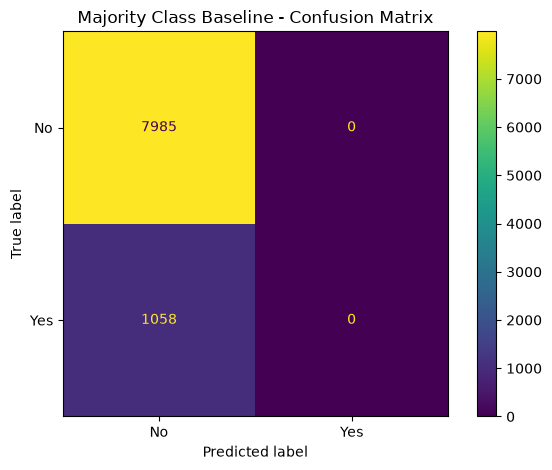

In [114]:
plot_confusion_matrix(
    y_true=y_test,
    y_pred=baseline_predictions,
    model_name="Majority Class Baseline",
)

## Evaluate baseline with ROC-AUC

In [115]:
baseline_results = evaluate_binary_classifier(
    model_name="Majority Class Baseline",
    y_true=y_test,
    y_pred=baseline_predictions,
    y_score=baseline_probabilities,
)

baseline_results

{'model': 'Majority Class Baseline',
 'accuracy': 0.8830034280659074,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5}

## ROC Curve

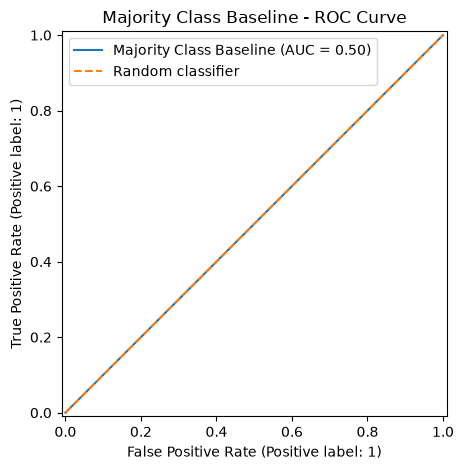

In [116]:
plot_roc_curve(
    y_true=y_test,
    y_score=baseline_probabilities,
    model_name="Majority Class Baseline",
)

## QDA and Gaussian Naive Bayes

The following models use the shared preprocessing framework.

Because QDA and Gaussian Naive Bayes require dense numerical input,
one-hot encoding is configured to produce a dense transformed matrix.

The current predictor set follows the preliminary preprocessing workflow
and may be updated after the final feature/leakage analysis.

In [117]:
numeric_features = [
    "age",
    "balance",
    "campaign",
    "previous",
]

categorical_features = [
    "job",
    "marital",
    "education",
    "housing",
    "loan",
    "contact",
    "month",
]

In [118]:
model_features = (
    numeric_features
    + categorical_features
)

X_model = X[model_features]

In [119]:
X_train_model, X_test_model, y_train_model, y_test_model = (
    train_test_split(
        X_model,
        y,
        test_size=0.20,
        stratify=y,
        random_state=42,
    )
)

In [120]:
qda_preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    dense_output=True,
)

In [121]:
student3_models = get_student3_models()

qda_model = student3_models[
    "Quadratic Discriminant Analysis"
]

In [122]:
qda_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            qda_preprocessor,
        ),
        (
            "classifier",
            qda_model,
        ),
    ]
)
qda_pipeline.fit(
    X_train_model,
    y_train_model,
)

LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.

QDA initially failed because the one-hot encoded feature matrix produced
collinear predictors, causing the class covariance matrix to be rank-deficient.

To stabilize covariance estimation, QDA was regularized using `reg_param`.